<a href="https://colab.research.google.com/github/ROHAN-BIT001/Predictive-Classification-using-Random-Forest/blob/main/Credit_Card_Fraud_Random_Forest_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Credit Card Fraud Detection — Random Forest

This project uses the provided `creditcard.csv` dataset.

**Flow:** load → inspect → analyse class imbalance → prepare data → train Random Forest → evaluate model.

The dataset is highly imbalanced. To keep the notebook manageable for a student project, a reproducible stratified sample of 60,000 rows is used for model training and testing. The original dataset is still loaded and inspected first.


## 1. Import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')


## 2. Load the dataset

In [ ]:
# In Google Colab, upload the provided creditcard.csv file
from google.colab import files

uploaded = files.upload()
csv_file = next(iter(uploaded))
df = pd.read_csv(csv_file)

print('Shape:', df.shape)
df.head()


Saving creditcard.csv to creditcard.csv
Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 3. Initial inspection

In [ ]:
df.info()

print('\\nMissing values:')
print(df.isnull().sum().sum())

print('Duplicate rows:', df.duplicated().sum())
print('\\nClass counts:')
print(df['Class'].value_counts())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

## 4. Analyse class imbalance

Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64


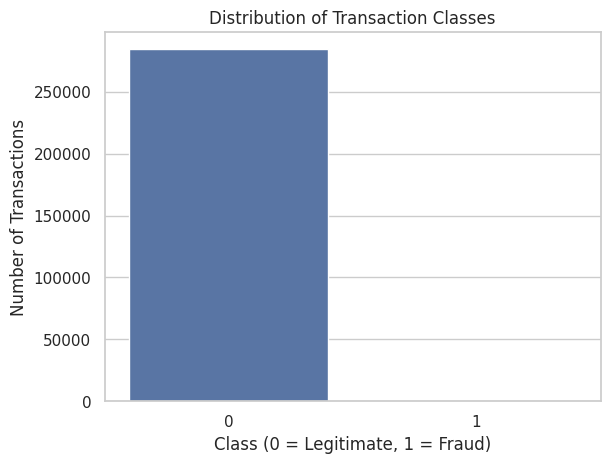

In [ ]:
# Class 0 = legitimate transaction, Class 1 = fraud
print((df['Class'].value_counts(normalize=True) * 100).round(4))

sns.countplot(data=df, x='Class')
plt.title('Distribution of Transaction Classes')
plt.xlabel('Class (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Number of Transactions')
plt.show()


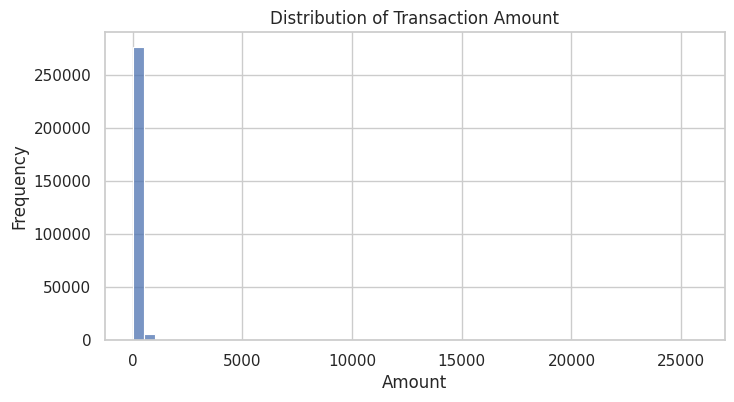

In [ ]:
# Transaction amount distribution
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x='Amount', bins=50)
plt.title('Distribution of Transaction Amount')
plt.xlabel('Amount')
plt.ylabel('Frequency')
plt.show()


## 5. Prepare data

In [ ]:
# Keep a reproducible, stratified sample to reduce training time
sample_size = 60000

# We can group by 'Class' and sample within each group without using the deprecated apply behavior
df_model = df.groupby('Class', group_keys=True).apply(
    lambda x: x.sample(
        n=min(len(x), max(1, round(sample_size * len(x) / len(df)))),
        random_state=42
    ),
    include_groups=False
).reset_index(level=0).reset_index(drop=True)

print('Sample shape:', df_model.shape)
print('Class counts in sample:')
print(df_model['Class'].value_counts())

# Separate input features and target
X = df_model.drop(columns=['Class'])
y = df_model['Class']

Sample shape: (60000, 31)
Class counts in sample:
Class
0    59896
1      104
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Training data:', X_train.shape)
print('Testing data:', X_test.shape)


Training data: (48000, 30)
Testing data: (12000, 30)


## 6. Train Random Forest model

In [ ]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=40,
    max_depth=10,
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=2
)

model.fit(X_train, y_train)
print('Model training completed')


Model training completed


## 7. Evaluate the model

In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    roc_curve
)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

print('Accuracy:', round(accuracy, 4))
print('Precision:', round(precision, 4))
print('Recall:', round(recall, 4))
print('F1-Score:', round(f1, 4))
print('ROC-AUC:', round(roc_auc, 4))
print('\\nClassification Report:')
print(classification_report(y_test, y_pred, digits=4, zero_division=0))


Accuracy: 0.9992
Precision: 0.8667
Recall: 0.619
F1-Score: 0.7222
ROC-AUC: 0.9258
\nClassification Report:
              precision    recall  f1-score   support

           0     0.9993    0.9998    0.9996     11979
           1     0.8667    0.6190    0.7222        21

    accuracy                         0.9992     12000
   macro avg     0.9330    0.8094    0.8609     12000
weighted avg     0.9991    0.9992    0.9991     12000



## 8. Confusion matrix

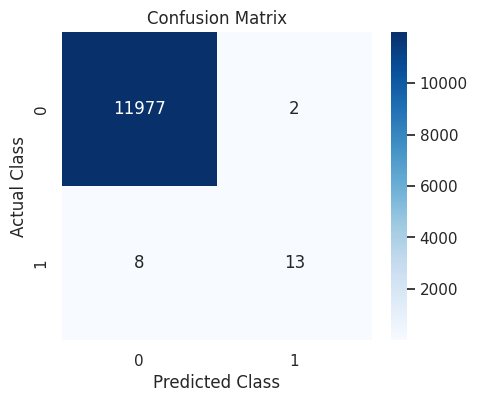

In [ ]:
conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.show()


## 9. ROC-AUC curve

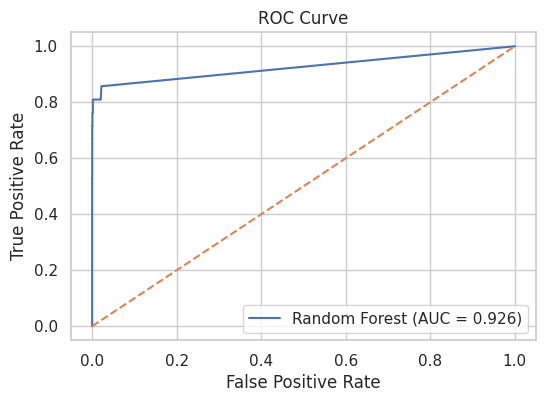

In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label=f'Random Forest (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.title('ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()


## 10. Feature importance

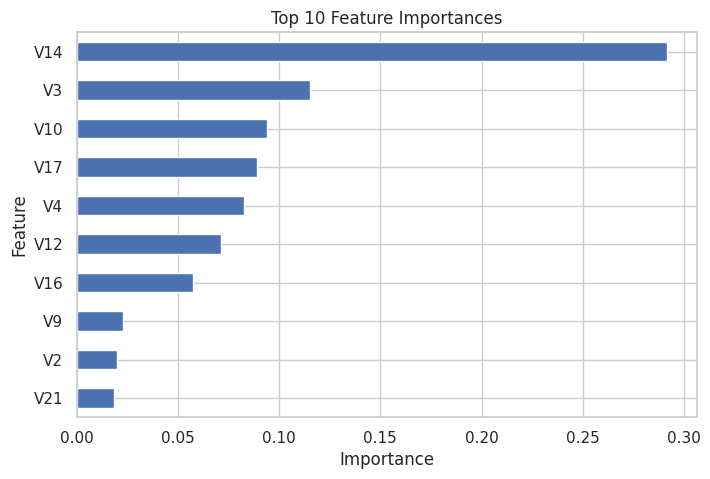

V14    0.291580
V3     0.115096
V10    0.094010
V17    0.089111
V4     0.082486
V12    0.071216
V16    0.057460
V9     0.023040
V2     0.020207
V21    0.018341
dtype: float64


In [ ]:
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
importance.head(10).sort_values().plot(kind='barh')
plt.title('Top 10 Feature Importances')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

print(importance.head(10))


## 11. Conclusion

The Random Forest model is evaluated using precision, recall, F1-score, the confusion matrix, and ROC-AUC. Accuracy alone is not enough for this dataset because fraud cases are rare. Recall shows how many actual fraud cases were detected, while precision shows how many transactions flagged as fraud were truly fraudulent.

The model was trained on a stratified 60,000-row sample to keep execution manageable. Results can vary slightly if the sampling or model settings are changed. The dataset contains anonymized V1–V28 features, so their real-world meanings are not provided.
